# Karpowicz 2025 — the Study

`Karpowicz2025CursorStability` turns the two NWB sessions into standardized events. **One timeline is one block**, 20 of them, following `wilson_2025`: a session is not a continuous recording (its blocks sit up to an hour apart and its block numbers skip), but a block is.

This notebook builds the Study on two blocks, one from each session, and reads every event family it emits back through an extractor.

In [1]:
import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np
import pandas as pd

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.karpowicz_2025.study import Karpowicz2025CursorStability
from neuralshed.extractors import BehavioralSeriesExtractor, NeuralFeatureExtractor

In [2]:
# Timeline 1 is a Simon block from the earlier session, timeline 11 is the later
# session's calibration block, which carries nearly every dropped bin in the release.
study = Karpowicz2025CursorStability(
    path=str(dataset_dir("karpowicz_2025") / "data"),
    query="timeline_index in [1, 11]",
)
events = study.run()

print(f"timelines in the full study: {study._info.num_timelines}")
print(f"events in this query: {len(events)} across {events.timeline.nunique()} timelines")
print(f"subject: {events.subject.unique()}")

timelines in the full study: 20
events in this query: 226 across 2 timelines
subject: <ArrowStringArray>
['Karpowicz2025CursorStability/T11']
Length: 1, dtype: str


In [3]:
print(events.type.value_counts().to_string())
print()
print("columns:", sorted(events.columns))

type
Intertrial              110
Action                  108
SpikeCounts               2
CursorPositionSeries      2
TargetPositionSeries      2
DecodedCursorVelocitySeries      2

columns: ['action_kind', 'block', 'code', 'dataset_id', 'description', 'dims', 'dropped_bins', 'duration', 'feature', 'filepath', 'frequency', 'is_calibration', 'kind', 'method', 'n_targets', 'normalization', 'participant_id', 'post_implant_day', 'processing', 'reference_frame', 'run', 'session', 'start', 'stop', 'study', 'subject', 'success', 'target_angle_deg', 'target_x', 'target_y', 'task', 'task_condition', 'threshold', 'timeline', 'trial_id', 'type', 'unit']


## What a timeline carries

Every row inherits the timeline's attributes, so a query can hold out a whole session, keep only the Simon blocks, or avoid the calibration block's dropped bins.

In [4]:
attributes = ["session", "block", "task", "is_calibration", "post_implant_day", "n_targets", "dropped_bins"]
events.groupby("timeline")[attributes].first()

,session,block,task,is_calibration,post_implant_day,n_targets,dropped_bins
timeline,,,,,,,
"Karpowicz2025CursorStability:block=3,dropped_bins=243,is_calibration=True,n_targets=8,post_implant_day=427,session=T11_day427,subject=T11,task=centeroutcalibration",T11_day427,3,centeroutcalibration,True,427,8,243
"Karpowicz2025CursorStability:block=5,dropped_bins=0,is_calibration=False,n_targets=4,post_implant_day=153,session=T11_day153,subject=T11,task=simonsequence",T11_day153,5,simonsequence,False,153,4,0


In [5]:
pd.crosstab(events.timeline, events.type)

type,Action,CursorPositionSeries,DecodedCursorVelocitySeries,Intertrial,SpikeCounts,TargetPositionSeries
timeline,,,,,,
"Karpowicz2025CursorStability:block=3,dropped_bins=243,is_calibration=True,n_targets=8,post_implant_day=427,session=T11_day427,subject=T11,task=centeroutcalibration",47,1,1,48,1,1
"Karpowicz2025CursorStability:block=5,dropped_bins=0,is_calibration=False,n_targets=4,post_implant_day=153,session=T11_day153,subject=T11,task=simonsequence",61,1,1,62,1,1


In [6]:
columns = ["type", "start", "duration", "code", "target_x", "target_y", "target_angle_deg", "success", "feature"]
one = events[events.timeline == events.timeline.iloc[0]]
one[columns].head(8)

,type,start,duration,code,target_x,target_y,target_angle_deg,success,feature
0,SpikeCounts,0.00,137.30,NaN,NaN,NaN,NaN,NaN,binned_spikes
1,CursorPositionSeries,0.00,137.30,NaN,NaN,NaN,NaN,NaN,cursor_pos
2,TargetPositionSeries,0.00,137.30,NaN,NaN,NaN,NaN,NaN,target_pos
3,DecodedCursorVelocitySeries,0.00,137.30,NaN,NaN,NaN,NaN,NaN,cursor_vel
4,Intertrial,0.00,7.54,NaN,NaN,NaN,NaN,NaN,NaN
5,Action,7.54,1.10,3.0,-0.38,0.0,180.0,True,NaN
6,Intertrial,8.64,0.18,NaN,NaN,NaN,NaN,NaN,NaN
7,Action,8.82,0.62,1.0,0.38,0.0,0.0,True,NaN


## Reading the four dense streams

All four share the block's 20 ms grid, so one segmenter reads them together. Triggering on `Action` gives one segment per movement, windowed to the first 600 ms, which is the span the paper defines intent over.

In [7]:
segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(target_unit="native", frequency=50, event_types="SpikeCounts"),
        "cursor": BehavioralSeriesExtractor(frequency=50, event_types="CursorPositionSeries"),
        "target": BehavioralSeriesExtractor(frequency=50, event_types="TargetPositionSeries"),
        "velocity": BehavioralSeriesExtractor(frequency=50, event_types="DecodedCursorVelocitySeries"),
    },
    trigger_query="type == 'Action'",
    duration=0.6,
)
segments = segmenter.apply(events)
segments.prepare()

print(f"one segment per movement: {len(segments)}")
print({key: tuple(np.asarray(value).shape) for key, value in segments[0].data.items()})

2026-08-25 19:30:47 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00, 111.10it/s]


2026-08-25 19:30:47 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


  0%|          | 0/2 [00:00<?, ?it/s]

...

100%|██████████| 2/2 [00:00<00:00, 2453.53it/s]


2026-08-25 19:30:47 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00, 2765.78it/s]

one segment per movement: 108
{'neural': (1, 192, 30), 'cursor': (1, 2, 30), 'target': (1, 2, 30), 'velocity': (1, 2, 30)}


The counts come back as counts per bin, and the velocity in the corrected `a.u./s`, so a segment's integrated velocity should match the distance the cursor actually covered.

In [8]:
batch = segments.load_all()
neural = np.asarray(batch.data["neural"])
cursor = np.asarray(batch.data["cursor"])
target = np.asarray(batch.data["target"])
velocity = np.asarray(batch.data["velocity"])

print(f"mean firing rate    : {neural.mean() * 50:.1f} Hz per channel")
print(f"counts are integral : {np.allclose(neural, np.round(neural))}")

travelled = np.linalg.norm(cursor[:, :, -1] - cursor[:, :, 0], axis=1)
integrated = np.linalg.norm((velocity / 50).sum(axis=2), axis=1)
print(f"cursor displacement vs integrated velocity: correlation {np.corrcoef(travelled, integrated)[0, 1]:.3f}")

mean firing rate    : 24.1 Hz per channel
counts are integral : True
cursor displacement vs integrated velocity: correlation 0.827


## The task rows line up with the streams

A movement ends on or near its cued target, which is the check that matters here: trial times were resolved against the source timestamps and then re-expressed in bins, precisely so the dropped bins in the calibration block cannot slide the task rows off the arrays they index into.

In [9]:
final = cursor[:, :, -1]
unit_target = target[:, :, -1] / np.linalg.norm(target[:, :, -1], axis=1, keepdims=True)
alignment = (final * unit_target).sum(axis=1) / np.linalg.norm(final, axis=1)

# Trigger columns come back as strings, so compare on the task label rather than the flag.
calibration = batch.triggers["task"].to_numpy() == "centeroutcalibration"
for label, mask in [("simon blocks", ~calibration), ("calibration block", calibration)]:
    print(f"{label:18s} cosine(cursor at 600 ms, cued target) = {np.median(alignment[mask]):.3f}")

simon blocks       cosine(cursor at 600 ms, cued target) = 0.983
calibration block  cosine(cursor at 600 ms, cued target) = 0.707


## The other event family

`Intertrial` covers the automatic recentring between movements. It carries no data of its own, so it is read by triggering on it and pulling the streams it spans.

In [10]:
gap_segmenter = ns.dataloader.Segmenter(
    extractors={"cursor": BehavioralSeriesExtractor(frequency=50, event_types="CursorPositionSeries")},
    trigger_query="type == 'Intertrial'",
    duration=0.2,
)
gaps = gap_segmenter.apply(events)
gaps.prepare()

gap_batch = gaps.load_all()
gap_cursor = np.asarray(gap_batch.data["cursor"])
print(f"intertrial segments: {len(gaps)}")
print(f"cursor distance from centre at the start of a gap: median {np.median(np.linalg.norm(gap_cursor[:, :, 0], axis=1)):.3f} a.u.")
print(f"and 200 ms later: median {np.median(np.linalg.norm(gap_cursor[:, :, -1], axis=1)):.3f} a.u.")

2026-08-25 19:30:47 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00, 2586.68it/s]

intertrial segments: 110
cursor distance from centre at the start of a gap: median 0.330 a.u.
and 200 ms later: median 0.063 a.u.


## Directional tuning, as a sanity check

Population rate around movement onset, split by cued direction, in the Simon block. The four traces separate, which is the minimum this dataset has to show before any decoding is attempted.

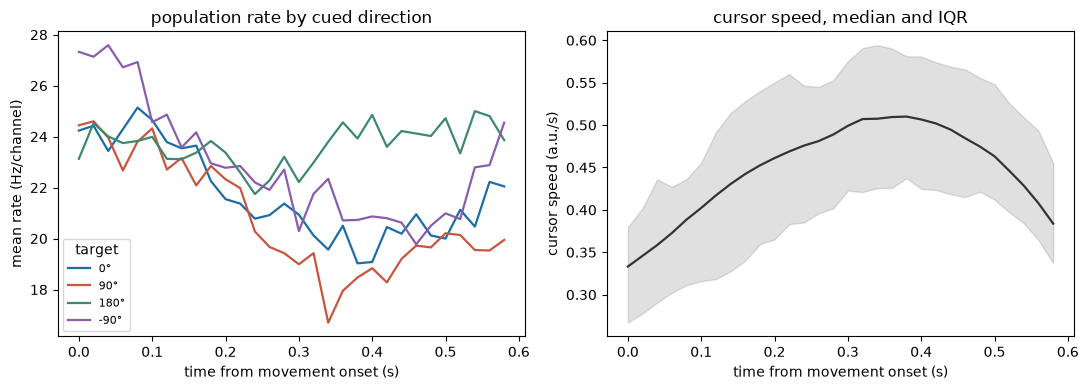

In [11]:
simon = ~calibration
angles = batch.triggers["target_angle_deg"].astype(float).to_numpy()[simon]
rates = neural[simon].mean(axis=1) * 50

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = {0.0: "#1b6ca8", 90.0: "#c8553d", 180.0: "#3c896d", -90.0: "#8a5cae"}
time = np.arange(rates.shape[1]) / 50

for angle, color in colors.items():
    mask = angles == angle
    axes[0].plot(time, rates[mask].mean(axis=0), color=color, label=f"{angle:.0f}°", linewidth=1.6)
axes[0].set(xlabel="time from movement onset (s)", ylabel="mean rate (Hz/channel)", title="population rate by cued direction")
axes[0].legend(title="target", fontsize=8)

speed = np.linalg.norm(velocity[simon], axis=1)
axes[1].plot(time, speed.mean(axis=0), color="#333333", linewidth=1.6)
axes[1].fill_between(time, np.percentile(speed, 25, axis=0), np.percentile(speed, 75, axis=0), color="#333333", alpha=0.15)
axes[1].set(xlabel="time from movement onset (s)", ylabel="cursor speed (a.u./s)", title="cursor speed, median and IQR")

figure.tight_layout()

## Summary

- 20 timelines, one per block, each emitting four dense 50 Hz streams plus one `Action` per movement and one `Intertrial` per gap.
- Counts come back integral, and integrated velocity tracks the distance the cursor covered, so the per-bin correction in `utils.get_stream` holds after extraction.
- Movements end on their cued target in both block kinds, including the calibration block whose grid is missing 243 bins.